[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LRCole3/pre-training-pathway/blob/main/09_pretraining_diffusion_transformers.ipynb)

# 09 · Pretraining Diffusion Transformers: Patches, Conditioning, Flow Matching and Training Accelerators

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Counting and embeddings | Count n-grams; learn word vectors | A first language model; similar words get similar vectors | Fixed window; one vector per word |
| 02 | RNNs, attention, ELMo | Carry a state; look back with attention; reuse the pretrained network | Context beyond a window; contextual features | Memory fades with distance; no parallel training |
| 03 | The transformer | Attention only, then today's block (RoPE, RMSNorm, SwiGLU, GQA, MoE) | Direct access to any earlier token; parallel training | Needs an objective and a transfer recipe |
| 04 | Objectives and transfer | Causal, masked and span-corruption pretraining | Representations that transfer with few labels | No objective wins everything; optimisation untested |
| 05 | Making it scale | Tokenisers, the optimiser recipe, scaling laws | A recipe that keeps improving with size | Discrete tokens only |
| 06 | VAE, GAN, pixel models | Generative models for images before diffusion | Sampling images at all | Blur, mode collapse, slow sampling |
| 07 | Diffusion design space | Denoise step by step; schedule, target, weighting | Quality and coverage together | Pixel space, MLP backbone, no text |
| 08 | Encoders, CLIP, latent diffusion | Pretrain the parts: vision encoder, text-image model, autoencoder | Conditioning and compression | The backbone still does not scale |
| **09** | **Diffusion transformers** | **Patch tokens, flow matching, training accelerators** | **A scalable denoiser** | **Base models still need post-training** |
| 10 | Capstone | One backbone, three objectives, two modalities | A unified view of pretraining | The post-training series starts here |

Notebook 07 worked out how to train a denoiser. Notebook 08 pretrained the parts around it. The denoiser itself was
still an MLP that reads an image as 64 unrelated numbers. From 2020 to 2022 the standard backbone was a
convolutional U-Net ([Ho et al., 2020](https://arxiv.org/abs/2006.11239), [Rombach et al., 2021](https://arxiv.org/abs/2112.10752)). In 2022 two papers replaced it with the plain transformer of
notebook 03, applied to image patches as in notebook 08: the Diffusion Transformer (DiT, [Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748)) and U-ViT
([Bao et al., 2022](https://arxiv.org/abs/2209.12152)). Today's large image and video generators are built this way ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)).

This notebook builds a diffusion transformer and opens its design choices one at a time:

* **size and tokens**: width, depth, and the patch size that sets the number of tokens;
* **conditioning route**: how the timestep and the label reach the tokens (adaLN-Zero, plain adaLN, cross-attention,
  in-context tokens);
* **position scheme**: learned, fixed sinusoidal, two-dimensional RoPE, or none;
* **the path between noise and data**: diffusion against flow matching ([Lipman et al., 2022](https://arxiv.org/abs/2210.02747), [Liu et al., 2022](https://arxiv.org/abs/2209.03003)), and how the
  time is sampled in training;
* **two training accelerators**: masked training ([Zheng et al., 2023](https://arxiv.org/abs/2306.09305), [Gao et al., 2023](https://arxiv.org/abs/2303.14389)) and alignment with a pretrained
  encoder (REPA, [Yu et al., 2024](https://arxiv.org/abs/2410.06940)).

It ends by saving a base diffusion transformer, the kind of model that the post-training series starts from.

## Learning objectives

1. Build a diffusion transformer from patch tokens, and explain what each conditioning route and position scheme
   does.
2. Relate sample quality to model size and to the number of tokens, and say when more compute helps.
3. Derive flow matching as a diffusion model with a straight path, train it, and compare it with diffusion at
   different numbers of sampling steps.
4. Explain masked training and representation alignment, and measure what each buys.

**Runtime:** 25 to 30 minutes on a laptop CPU (22 diffusion transformers; most train in about a minute, the slowest in under three).

In [1]:
# Setup. Locally this only adds the repo to the path. In Colab it first clones the repository (untested path).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("prelib"):
    os.system("git clone -q https://github.com/LRCole3/pre-training-pathway.git"); os.chdir("pre-training-pathway")
sys.path.insert(0, ".")

import time, math, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from prelib import dit as T, diffusion as D, vision as V, generative as G, images, metrics, viz, set_seed, CKPT_DIR
viz.style()
torch.set_num_threads(min(4, torch.get_num_threads()))
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
Xtr, ytr, Xte, yte = images.load_digits_tensor()
judge = images.get_judge()
card = metrics.ImageScorecard(judge, Xtr, Xte, yte)
N = len(Xte)
LABELS = ytr[torch.randperm(len(ytr), generator=torch.Generator().manual_seed(0))[:N]]     # the digits we ask for
BASE = dict(schedule="cosine", pred="x0", weighting="min-snr")                              # the final recipe of notebook 07

ROWS, RUNS = {}, {}
def score(x, name, nfe, keep=True):
    row = card.evaluate(x, name, nfe=nfe, labels=LABELS); card.rows.pop()
    if keep:
        ROWS[name] = row
    return row

def run(name, diff=None, steps=1500, seed=0, track=False, sampler=None, **arch):
    # Train one diffusion transformer and keep it in RUNS[name]. track=True also measures the FD of its samples every 250 steps.
    # diff: the training objective (default: the recipe of notebook 07). sampler: what to sample with, when diff is a wrapper around it.
    diff = diff or D.Diffusion(**BASE); sampler = sampler or diff
    set_seed(seed); net = T.DiT(**arch); log = {}
    def measure(step, raw, ema):
        log[step] = score(sampler.sample(ema, LABELS, steps=50), "in training", 50, keep=False)["fd"]
    out = D.train(net, diff, Xtr, ytr, steps=steps, seed=seed, callback=measure if track else None, every=250)
    out.update(diff=sampler, track=pd.Series(log, name=name) if track else None, params=net.n_params(), cost=net.cost())
    RUNS[name] = out
    return out

def sample(name, steps=50, w=0.0, labels=None, **kw):
    r = RUNS[name]
    return r["diff"].sample(r["model"], LABELS if labels is None else labels, steps=steps, w=w, **kw)

def report(name, row=None, steps=50, w=0.0, keep=True):
    return score(sample(name, steps=steps, w=w), row or name, nfe=steps * (2 if w else 1), keep=keep)

def summary(names):
    # one row per trained model: size, compute, training time, and the scores of 359 samples (50 steps; FD also with 10 steps)
    rows = {}
    for n in names:
        r = ROWS[n] if n in ROWS else report(n)
        rows[n] = {"parameters (k)": RUNS[n]["params"] / 1e3, "compute per pass (M)": RUNS[n]["cost"], "training seconds": RUNS[n]["seconds"], "fd": r["fd"], "precision": r["precision"],
                   "coverage": r["coverage"], "judge reads the requested digit": r["judge_acc"], "fd with 10 steps": report(n, steps=10, keep=False)["fd"]}
    return pd.DataFrame(rows).T.round({"parameters (k)": 0, "compute per pass (M)": 1, "training seconds": 0, "fd": 1, "precision": 2, "coverage": 2, "judge reads the requested digit": 2, "fd with 10 steps": 1})

earlier = metrics.load_scorecard(); earlier = earlier[earlier.notebook.isin(["06_image_generators", "07_diffusion"])].set_index("model")
print(f"{len(Xtr)} training images, {N} held-out images. Real data score FD {earlier.loc['real data', 'fd'].iloc[0]:.1f}; the final recipe of notebook 07 (MLP, 1.1 million parameters, 3,000 steps) scored {earlier.loc['final recipe', 'fd']:.1f}.")

1438 training images, 359 held-out images. Real data score FD 5.4; the final recipe of notebook 07 (MLP, 1.1 million parameters, 3,000 steps) scored 7.0.


## 1. From an MLP to a transformer

A diffusion transformer has four parts.

1. **Patchify.** Cut the noisy image into patches and map each patch to a token with one linear layer, exactly as
   the vision transformer of notebook 08 does. With 2×2 patches an 8×8 image is 16 tokens.
2. **Positions.** Tell each token where its patch came from.
3. **Blocks.** A stack of transformer blocks (attention, then a feed-forward layer). Every block must also know the
   timestep and the label. How it is told is the conditioning route of section 3.
4. **Unpatchify.** A last linear layer maps each token back to the pixels of its patch.

The network has the same signature as the MLP of notebook 07: noisy image, timestep and label in, a prediction of
the same size as the image out. So nothing else changes. We train it with the final recipe of notebook 07 (cosine
schedule, the network predicts the clean image, min-SNR weight) and compare it with the MLP of that notebook at the
same number of steps. Every run in this notebook uses 1,500 training steps unless stated; the baseline is trained
with two seeds, and one of them is measured during training.

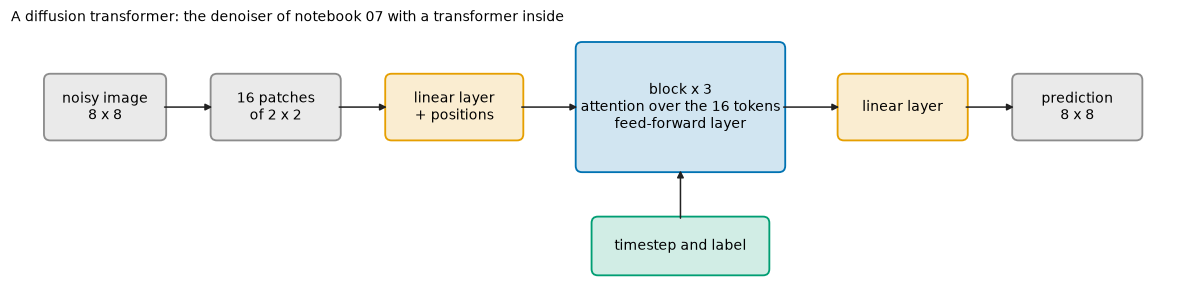

,parameters (k),compute per pass (M),training seconds,fd,precision,coverage,judge reads the requested digit,fd with 10 steps
MLP of notebook 07,299.0,NaN,7.0,11.2,0.93,0.93,0.93,12.4
baseline,247.0,2.4,49.0,8.1,0.91,0.93,0.96,9.8
"baseline, seed 1",247.0,2.4,44.0,8.0,0.93,0.90,0.96,9.9


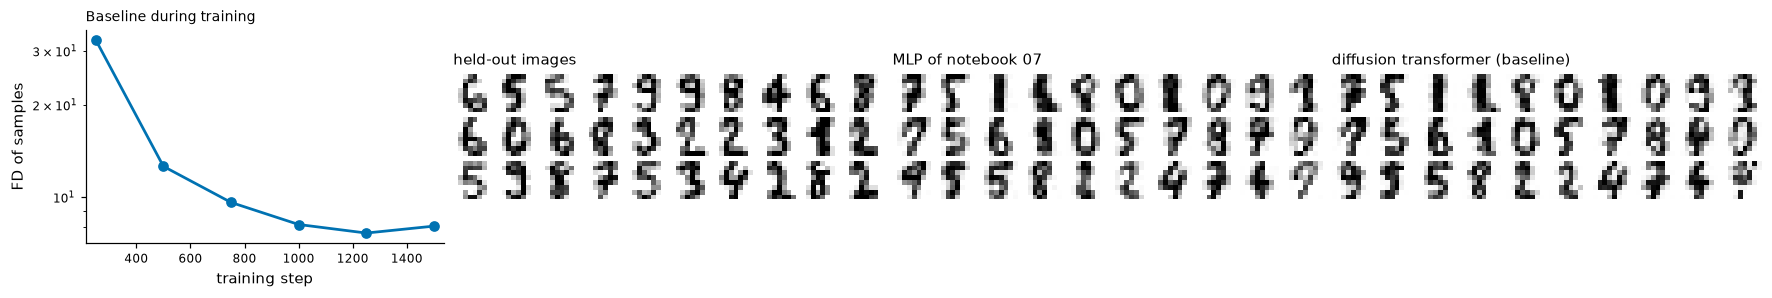

In [2]:
fig, ax = plt.subplots(figsize=(13, 2.6))
viz.diagram(ax, [(0, 1.0, 1.5, 0.8, "noisy image\n8 x 8", viz.GREY), (2.1, 1.0, 1.6, 0.8, "16 patches\nof 2 x 2", viz.GREY), (4.3, 1.0, 1.7, 0.8, "linear layer\n+ positions", viz.ORANGE),
                  (6.7, 0.6, 2.6, 1.6, "block x 3\nattention over the 16 tokens\nfeed-forward layer", viz.BLUE), (10.0, 1.0, 1.6, 0.8, "linear layer", viz.ORANGE), (12.2, 1.0, 1.6, 0.8, "prediction\n8 x 8", viz.GREY),
                  (6.9, -0.7, 2.2, 0.7, "timestep and label", viz.GREEN)],
            [(1.5, 1.4, 2.1, 1.4), (3.7, 1.4, 4.3, 1.4), (6.0, 1.4, 6.7, 1.4), (9.3, 1.4, 10.0, 1.4), (11.6, 1.4, 12.2, 1.4), (8.0, 0.0, 8.0, 0.6)])
ax.set_title("A diffusion transformer: the denoiser of notebook 07 with a transformer inside", fontsize=9)
plt.show()

set_seed(0); mlp_net = D.Denoiser(128, 3); mlp_diff = D.Diffusion(**BASE)
mlp = D.train(mlp_net, mlp_diff, Xtr, ytr, steps=1500, seed=0)
mlp.update(diff=mlp_diff, params=sum(p.numel() for p in mlp_net.parameters()), cost=float("nan")); RUNS["MLP of notebook 07"] = mlp
run("baseline", track=True); run("baseline, seed 1", seed=1)
display(summary(["MLP of notebook 07", "baseline", "baseline, seed 1"]))
fig, axes = plt.subplots(1, 4, figsize=(16, 2.6), gridspec_kw=dict(width_ratios=[1, 1.2, 1.2, 1.2]))
RUNS["baseline"]["track"].plot(ax=axes[0], marker="o", color=viz.BLUE); axes[0].set_yscale("log"); axes[0].set_xlabel("training step"); axes[0].set_ylabel("FD of samples"); axes[0].set_title("Baseline during training", fontsize=9)
for ax, (title, x) in zip(axes[1:], (("held-out images", Xte), ("MLP of notebook 07", sample("MLP of notebook 07")), ("diffusion transformer (baseline)", sample("baseline")))):
    images.show_grid(x[:30], nrow=10, ax=ax, title=title)
plt.show()

**What happened.**

* **Better samples at the same number of steps.** The diffusion transformer reaches an FD of 8.1 and 8.0 in two
  seeds. The MLP reaches 11.2 with the same recipe and the same 1,500 steps, and it has more parameters (299,000
  against 247,000). The judge reads 0.96 of the transformer's samples as the requested digit, against 0.93. With 10
  sampling steps the order is the same (9.8 against 12.4).
* **Two seeds differ by 0.1.** Differences of a few tenths between runs below mean nothing; differences of a point
  or more do.
* **The price is time.** On a CPU the transformer takes about six times as long to train: 44 s against 7 s, for
  the run that is not measured during training (see the column of training seconds). The MLP multiplies a few
  matrices. The transformer runs attention over 16 tokens in each of
  three blocks. Given the same *time*, the MLP is not behind: notebook 07 trained a wider MLP for 3,000 steps in
  about 25 seconds and reached 7.0.

So on this problem the transformer is the better model per training step and not yet per second. Section 8 trains
it for longer and returns to the comparison.

## 2. Design choice: size, and the number of tokens

The main empirical result of [Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748) is that the quality of a diffusion transformer follows its **compute
per forward pass**, and that it does not matter much where the compute comes from: a wider model, a deeper model, or
more tokens. The number of tokens is set by the **patch size**. Halving the patch side gives four times as many
tokens and about four times the compute, with almost the same number of parameters. In their experiments smaller
patches were consistently better.

We vary the size in both ways:

* width and depth: 32 wide with 2 blocks, 64 with 3 (the baseline), 96 with 4;
* patch size: 4×4 pixels (4 tokens), 2×2 (16 tokens, the baseline), 1×1 (64 tokens, one per pixel).

,parameters (k),compute per pass (M),training seconds,fd,precision,coverage,judge reads the requested digit,fd with 10 steps
"width 32, 2 blocks",46.0,0.4,22.0,14.6,0.85,0.80,0.89,17.5
baseline,247.0,2.4,49.0,8.1,0.91,0.93,0.96,9.8
"baseline, seed 1",247.0,2.4,44.0,8.0,0.93,0.90,0.96,9.9
"width 96, 4 blocks",713.0,7.2,77.0,6.3,0.95,0.92,0.98,7.4
patch 4 (4 tokens),248.0,0.6,22.0,6.3,0.94,0.93,0.95,7.7
"patch 4 (4 tokens), seed 1",248.0,0.6,26.0,6.3,0.95,0.91,0.97,7.5
patch 1 (64 tokens),250.0,10.2,153.0,13.4,0.86,0.83,0.92,16.0


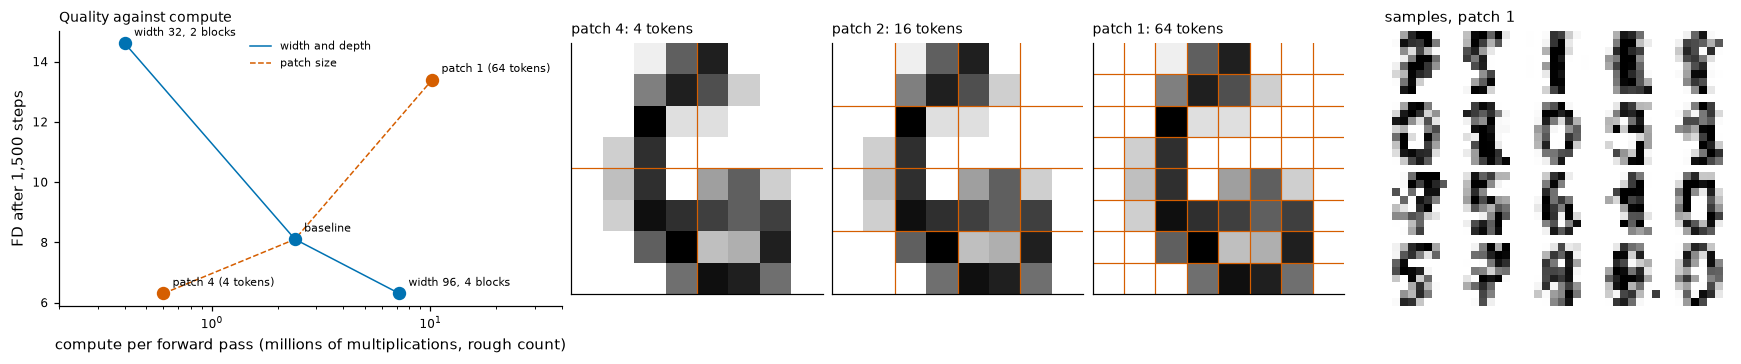

In [3]:
SIZES = {"width 32, 2 blocks": dict(d=32, depth=2), "width 96, 4 blocks": dict(d=96, depth=4), "patch 4 (4 tokens)": dict(patch=4), "patch 1 (64 tokens)": dict(patch=1)}
for name, arch in SIZES.items():
    run(name, **arch)
run("patch 4 (4 tokens), seed 1", patch=4, seed=1)
size_names = ["width 32, 2 blocks", "baseline", "baseline, seed 1", "width 96, 4 blocks", "patch 4 (4 tokens)", "patch 4 (4 tokens), seed 1", "patch 1 (64 tokens)"]
size_table = summary(size_names)
display(size_table)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), gridspec_kw=dict(width_ratios=[1.6, 0.8, 0.8, 0.8, 1.3]))
ax = axes[0]
for n, col in (("width 32, 2 blocks", viz.BLUE), ("baseline", viz.BLUE), ("width 96, 4 blocks", viz.BLUE), ("patch 4 (4 tokens)", viz.VERMILION), ("patch 1 (64 tokens)", viz.VERMILION)):
    ax.scatter(size_table.loc[n, "compute per pass (M)"], size_table.loc[n, "fd"], s=60, color=col, zorder=3)
    ax.annotate(n, (size_table.loc[n, "compute per pass (M)"], size_table.loc[n, "fd"]), textcoords="offset points", xytext=(6, 5), fontsize=7)
ax.plot(size_table.loc[["width 32, 2 blocks", "baseline", "width 96, 4 blocks"], "compute per pass (M)"], size_table.loc[["width 32, 2 blocks", "baseline", "width 96, 4 blocks"], "fd"], color=viz.BLUE, lw=1, label="width and depth")
ax.plot(size_table.loc[["patch 4 (4 tokens)", "baseline", "patch 1 (64 tokens)"], "compute per pass (M)"], size_table.loc[["patch 4 (4 tokens)", "baseline", "patch 1 (64 tokens)"], "fd"], color=viz.VERMILION, lw=1, ls="--", label="patch size")
ax.set_xscale("log"); ax.set_xlim(0.2, 40); ax.set_xlabel("compute per forward pass (millions of multiplications, rough count)"); ax.set_ylabel("FD after 1,500 steps"); ax.set_title("Quality against compute", fontsize=9); ax.legend(fontsize=7, loc="upper center")
for ax, p in zip(axes[1:4], (4, 2, 1)):
    ax.imshow(Xte[0].view(8, 8), cmap="gray_r", vmin=-1, vmax=1)
    for k in range(p, 8, p):
        ax.axhline(k - 0.5, color=viz.VERMILION, lw=0.8); ax.axvline(k - 0.5, color=viz.VERMILION, lw=0.8)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"patch {p}: {(8 // p) ** 2} tokens", fontsize=9)
images.show_grid(sample("patch 1 (64 tokens)")[:20], nrow=5, ax=axes[4], title="samples, patch 1")
plt.show()

**What happened.** Two different answers.

* **Width and depth: quality follows compute**, as [Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748) found. From the smallest model to the largest
  the rough count of compute per pass rises from 0.4 to 2.4 to 7.2 million multiplications, and FD falls from 14.6
  to 8.1 to 6.3.
* **Patch size: the opposite of their finding.** Four large patches (a quarter of the baseline's compute) give 6.3
  in both seeds, better than the baseline's 8.1. Sixty-four patches of one pixel (four times the compute, and the
  slowest model of this notebook per training step) give 13.4.

Why would more tokens hurt here? Two reasons seem likely; the notebook tests neither.

* A 4×4 patch of our images is 16 numbers, and the linear layer maps it to 64. Nothing is lost by using large
  patches. In DiT a patch is cut from the latent code of a large image, and a large patch squeezes many numbers
  into one token.
* With one pixel per token the model has to learn from the data which pixels belong together, and 1,500 steps are
  not enough. In a development run with 3,000 steps, which is not part of this notebook, the models with 4, 16 and
  64 tokens scored 5.5, 6.1 and 6.4: the gap nearly closes, and the order does not reverse.

"More tokens are better" is a statement about images with detail that large patches lose. Ours have none.

## 3. Design choice: how the timestep and the label reach the tokens

The tokens carry the noisy image. The network also needs the timestep and the label. [Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748) compared ways
of delivering them, and the four below are all in use somewhere.

| Route | How it works | Where it is used |
|---|---|---|
| **In-context** | The timestep and the label become two extra tokens in the sequence | U-ViT ([Bao et al., 2022](https://arxiv.org/abs/2209.12152)) |
| **Cross-attention** | Each block gets a second attention layer that reads the condition tokens | Text in latent diffusion ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)) |
| **adaLN** | The condition sets a scale and a shift after each normalisation layer (FiLM, [Perez et al., 2017](https://arxiv.org/abs/1709.07871)) | Class-conditional models |
| **adaLN-Zero** | adaLN plus a gate on each block's output, initialised at zero, so every block starts as the identity | DiT ([Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748)) |

adaLN has no extra tokens and no extra attention, so it is the cheapest. It can only carry a condition that fits in
one vector, which is why text, a sequence, is fed by cross-attention or as tokens. The zero gate is an instance of
an old idea: start a deep network as the identity so that the first gradient steps are well behaved.

The baseline uses adaLN-Zero. We train the other three.

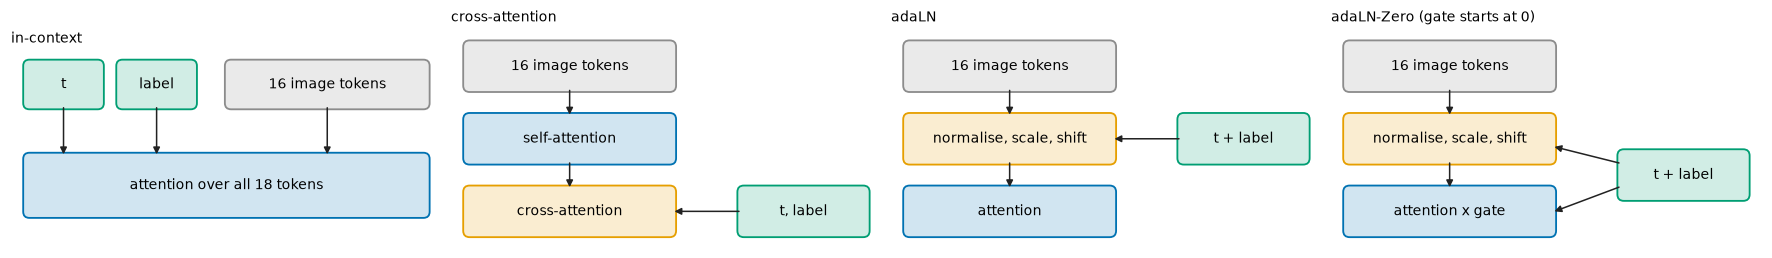

,parameters (k),compute per pass (M),training seconds,fd,precision,coverage,judge reads the requested digit,fd with 10 steps
baseline,247.0,2.4,49.0,8.1,0.91,0.93,0.96,9.8
"baseline, seed 1",247.0,2.4,44.0,8.0,0.93,0.90,0.96,9.9
adaLN (no gate),222.0,2.4,66.0,7.8,0.91,0.89,0.94,9.5
cross-attention,215.0,2.4,70.0,11.5,0.89,0.85,0.94,13.6
in-context,165.0,2.7,60.0,10.0,0.89,0.88,0.92,12.2


FD during training, adaLN-Zero (baseline) against adaLN without the gate:


,250,500,750,1000,1250,1500
adaLN-Zero,32.6,12.6,9.6,8.2,7.6,8.1
adaLN (no gate),41.2,13.5,9.8,7.6,7.7,7.8


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 2.7))
B, O, G_, K = viz.BLUE, viz.ORANGE, viz.GREEN, viz.GREY
viz.diagram(axes[0], [(0, 1.6, 1.0, 0.6, "t", G_), (1.2, 1.6, 1.0, 0.6, "label", G_), (2.6, 1.6, 2.6, 0.6, "16 image tokens", K), (0, 0.2, 5.2, 0.8, "attention over all 18 tokens", B)],
            [(0.5, 1.6, 0.5, 1.0), (1.7, 1.6, 1.7, 1.0), (3.9, 1.6, 3.9, 1.0)]); axes[0].set_title("in-context", fontsize=9)
viz.diagram(axes[1], [(0, 1.8, 2.6, 0.6, "16 image tokens", K), (0, 0.9, 2.6, 0.6, "self-attention", B), (0, 0.0, 2.6, 0.6, "cross-attention", O), (3.4, 0.0, 1.6, 0.6, "t, label", G_)],
            [(1.3, 1.8, 1.3, 1.5), (1.3, 0.9, 1.3, 0.6), (3.4, 0.3, 2.6, 0.3)]); axes[1].set_title("cross-attention", fontsize=9)
viz.diagram(axes[2], [(0, 1.8, 2.6, 0.6, "16 image tokens", K), (0, 0.9, 2.6, 0.6, "normalise, scale, shift", O), (0, 0.0, 2.6, 0.6, "attention", B), (3.4, 0.9, 1.6, 0.6, "t + label", G_)],
            [(1.3, 1.8, 1.3, 1.5), (1.3, 0.9, 1.3, 0.6), (3.4, 1.2, 2.6, 1.2)]); axes[2].set_title("adaLN", fontsize=9)
viz.diagram(axes[3], [(0, 1.8, 2.6, 0.6, "16 image tokens", K), (0, 0.9, 2.6, 0.6, "normalise, scale, shift", O), (0, 0.0, 2.6, 0.6, "attention x gate", B), (3.4, 0.45, 1.6, 0.6, "t + label", G_)],
            [(1.3, 1.8, 1.3, 1.5), (1.3, 0.9, 1.3, 0.6), (3.4, 0.9, 2.6, 1.1), (3.4, 0.6, 2.6, 0.3)]); axes[3].set_title("adaLN-Zero (gate starts at 0)", fontsize=9)
plt.show()

ROUTES = {"adaLN (no gate)": "adaln", "cross-attention": "cross", "in-context": "in-context"}
for name, cond in ROUTES.items():
    run(name, cond=cond, track=(cond == "adaln"))
route_names = ["baseline", "baseline, seed 1", "adaLN (no gate)", "cross-attention", "in-context"]
display(summary(route_names))
print("FD during training, adaLN-Zero (baseline) against adaLN without the gate:")
display(pd.DataFrame({"adaLN-Zero": RUNS["baseline"]["track"], "adaLN (no gate)": RUNS["adaLN (no gate)"]["track"]}).T.round(1))

**What happened.**

* **The two adaLN variants are the best**: 8.1 and 8.0 with the zero-initialised gate, 7.8 without it.
* **In-context tokens (10.0) and cross-attention (11.5) are behind**, far outside the 0.1 between seeds.
  [Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748) also found both behind adaLN-Zero. Cross-attention was also the slowest of the four to train
  (70 s, against 44 s for the baseline run that is not measured during training), because every block has a second
  attention layer.
* **The zero gate made no difference at the end.** It helped early (FD 32.6 against 41.2 at step 250), and by step
  750 the two were level. Our model has three blocks. The argument for starting every block as the identity is an
  argument about deep stacks, and this notebook does not test one.

adaLN wins here with a condition that fits in one vector. For text, a sequence, the choice is between
cross-attention and tokens in the sequence, and adaLN carries only a pooled summary ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)).

## 4. Design choice: positions

Attention treats its input as a set (notebook 03). Without position information a diffusion transformer cannot know
which token is the top-left patch, and it cannot put a stroke in the right place. Four schemes:

* **Learned**: one trainable vector per patch position, added to the token. The choice of the first vision
  transformers, and of our baseline.
* **Fixed sinusoidal, in two dimensions**: half of the vector encodes the row and half the column, with the sines
  and cosines of notebook 03. This is what DiT uses.
* **Two-dimensional RoPE**: no vector is added. Inside every attention layer, queries and keys are rotated by
  angles that depend on the row (half of the coordinates) and the column (the other half), so that attention scores
  depend on the *offset* between two patches. This extends the RoPE of notebook 03 to a grid. Recent diffusion
  transformers adopt it because it carries over to resolutions and aspect ratios not seen in training
  ([Lu et al., 2024](https://arxiv.org/abs/2402.12376)).
* **None**, as a control.

,parameters (k),compute per pass (M),training seconds,fd,precision,coverage,judge reads the requested digit,fd with 10 steps
baseline,247.0,2.4,49.0,8.1,0.91,0.93,0.96,9.8
"baseline, seed 1",247.0,2.4,44.0,8.0,0.93,0.90,0.96,9.9
fixed sinusoidal positions,246.0,2.4,60.0,6.4,0.95,0.92,0.95,7.8
"fixed sinusoidal positions, seed 1",246.0,2.4,61.0,6.6,0.94,0.90,0.97,8.1
2-D RoPE,246.0,2.4,69.0,7.9,0.89,0.89,0.92,9.7
no positions,246.0,2.4,49.0,141.6,0.36,0.13,0.12,130.5


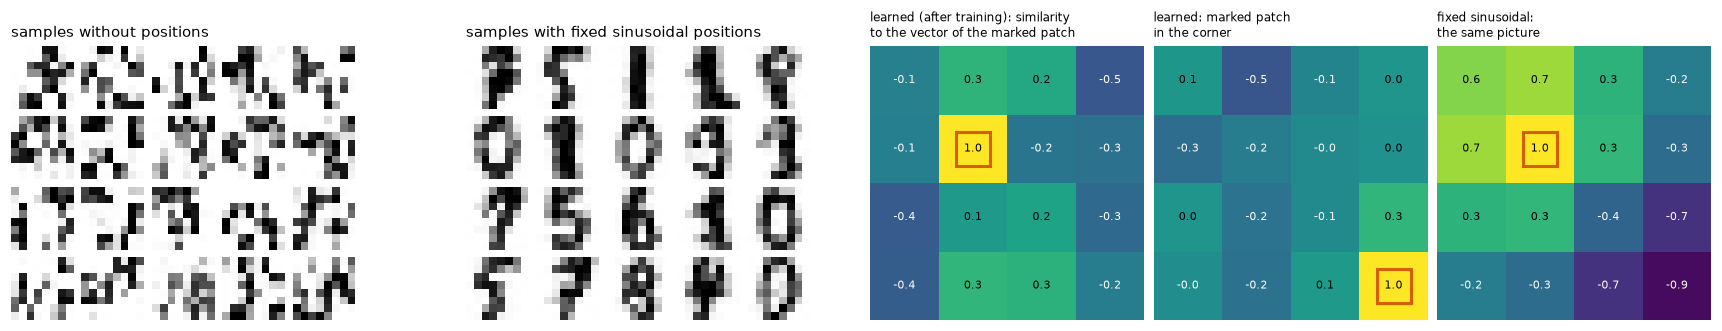

learned positions, after training: mean similarity of the vectors of adjacent patches 0.08, of patches further apart -0.10
fixed sinusoidal positions: mean similarity of the vectors of adjacent patches 0.69, of patches further apart -0.25


In [5]:
POSITIONS = {"fixed sinusoidal positions": "sincos", "2-D RoPE": "rope", "no positions": "none"}
for name, pos in POSITIONS.items():
    run(name, pos=pos)
run("fixed sinusoidal positions, seed 1", pos="sincos", seed=1)
pos_names = ["baseline", "baseline, seed 1", "fixed sinusoidal positions", "fixed sinusoidal positions, seed 1", "2-D RoPE", "no positions"]
display(summary(pos_names))

fig, axes = plt.subplots(1, 5, figsize=(16, 2.9), gridspec_kw=dict(width_ratios=[1.3, 1.3, 0.8, 0.8, 0.8]))
images.show_grid(sample("no positions")[:20], nrow=5, ax=axes[0], title="samples without positions")
images.show_grid(sample("fixed sinusoidal positions")[:20], nrow=5, ax=axes[1], title="samples with fixed sinusoidal positions")
def directions(table):
    # position vectors with their mean removed, scaled to unit length, so that a dot product is a cosine similarity
    return torch.nn.functional.normalize(table - table.mean(0, keepdim=True), dim=-1)
pos, fixed = directions(RUNS["baseline"]["model"].pos.detach()), directions(T.sincos_2d(4, 64))
for ax, (table, q, title) in zip(axes[2:], ((pos, 5, "learned (after training): similarity\nto the vector of the marked patch"), (pos, 15, "learned: marked patch\nin the corner"), (fixed, 5, "fixed sinusoidal:\nthe same picture"))):
    sim = (table @ table[q]).view(4, 4).numpy()
    viz.heat(ax, sim, annotate=True, fmt="{:.1f}", cmap="viridis", vmin=-1, vmax=1); ax.set_xticks([]); ax.set_yticks([]); ax.plot([q % 4], [q // 4], marker="s", ms=22, mfc="none", mec=viz.VERMILION, mew=2)
    ax.set_title(title, fontsize=8)
plt.show()
rows_, cols_ = T.grid_positions(4); apart = ((rows_[:, None] - rows_[None]) ** 2 + (cols_[:, None] - cols_[None]) ** 2).sqrt()
for name, table in (("learned positions, after training", pos), ("fixed sinusoidal positions", fixed)):
    S = table @ table.T
    print(f"{name}: mean similarity of the vectors of adjacent patches {float(S[apart == 1].mean()):.2f}, of patches further apart {float(S[apart > 1].mean()):.2f}")

**What happened.**

* **Without positions the model fails completely**: FD 141.6, and the judge reads 0.12 of the samples as the
  requested digit, close to chance. The left panel shows why. The patches look like pieces of digits, placed
  anywhere.
* **Fixed sinusoidal positions were the best**: 6.4 and 6.6 in two seeds, against 8.1 and 8.0 for learned
  positions. The heat maps and the two printed lines suggest a reason. The fixed vectors describe the grid from the
  first step: vectors of adjacent patches are similar (0.69 on average) and vectors of patches further apart are not
  (−0.25). The learned vectors start as noise, and after 1,500 steps they show only a faint trace of the grid (0.08
  against −0.10).
* **2-D RoPE (7.9) is level with learned positions** and behind the fixed sinusoids. At a single resolution it
  brought nothing. Its claimed advantage, sampling at resolutions and shapes not seen in training ([Lu et al., 2024](https://arxiv.org/abs/2402.12376)),
  cannot be tested with images of one size. This is the same pattern as in notebook 03, where RoPE was level with
  the other schemes on documents of the training length and ahead only on longer ones.

### Try it: choose an architecture

Static preview at the default settings {'model': 'baseline', 'sampling_steps': 50, 'seed': 0}. Run the notebook to get the controls.


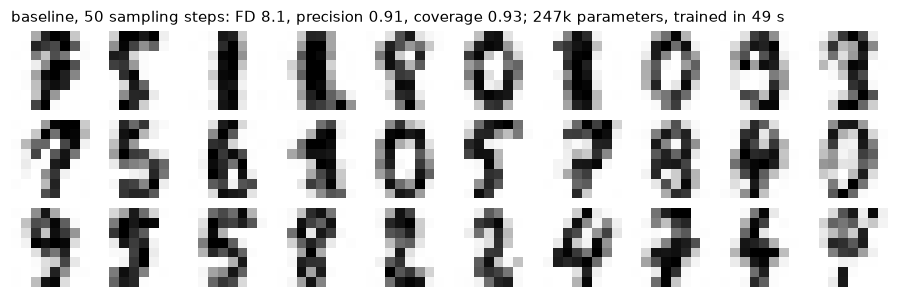

In [6]:
VARIANTS = ["baseline", "width 32, 2 blocks", "width 96, 4 blocks", "patch 4 (4 tokens)", "patch 1 (64 tokens)", "adaLN (no gate)", "cross-attention", "in-context",
            "fixed sinusoidal positions", "2-D RoPE", "no positions", "MLP of notebook 07"]
def architecture_explorer(model="baseline", sampling_steps=50, seed=0):
    x = sample(model, steps=sampling_steps, seed=seed); r = score(x, model, sampling_steps, keep=False)
    fig, ax = plt.subplots(figsize=(9, 2.6))
    images.show_grid(x[:30], nrow=10, ax=ax, title=f"{model}, {sampling_steps} sampling steps: FD {r['fd']:.1f}, precision {r['precision']:.2f}, coverage {r['coverage']:.2f}; "
                     f"{RUNS[model]['params'] / 1e3:.0f}k parameters, trained in {RUNS[model]['seconds']:.0f} s")
    plt.show()
viz.explore(architecture_explorer, model=VARIANTS, sampling_steps=(2, 50, 1, 50), seed=(0, 9, 1, 0))

## 5. Design choice: the path between data and noise. Flow matching

Notebook 07 mixed image and noise as $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$. The two
coefficients satisfy $a^2 + b^2 = 1$, so as $t$ runs from 0 to 1,000 the pair moves along a quarter circle, and the
schedule decides how fast.

**Flow matching** ([Lipman et al., 2022](https://arxiv.org/abs/2210.02747)), in the form called rectified flow ([Liu et al., 2022](https://arxiv.org/abs/2209.03003)), uses the simplest path
there is, a straight line from the image to the noise, with a time $s$ between 0 and 1:

$$x_s = (1 - s)\,x_0 + s\,\epsilon .$$

Along a straight line the velocity is constant, $\tfrac{d x_s}{d s} = \epsilon - x_0$, and that is the training
target:

$$\mathcal{L} = \mathbb{E}_{x_0,\,\epsilon,\,s}\;\big\lVert v_\theta(x_s, s, c) - (\epsilon - x_0) \big\rVert^2 .$$

Sampling integrates the learned velocity from $s = 1$ (noise) to $s = 0$ (data) with Euler steps,
$x \leftarrow x - \Delta s \cdot v_\theta$.

In the terms of notebook 07 this is one more choice of schedule (the straight line) and of target (the velocity,
which is a mixture of noise and image like $v$). It has no $\bar\alpha_t$, no table of coefficients and no special
sampler. [Ma et al., 2024](https://arxiv.org/abs/2401.08740) made exactly this change inside the DiT architecture (SiT) and reported better results, and
Stable Diffusion 3 ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)) adopted it at scale. The usual argument for it is that straighter paths can be
followed with fewer sampling steps.

One more choice came with it: **how $s$ is drawn in training**. Uniformly is the obvious way. [Esser et al., 2024](https://arxiv.org/abs/2403.03206) found
it better to draw $s$ from a logit-normal distribution, which puts more training on the middle of the path, where
the image is neither clean nor pure noise.

We train the baseline architecture with flow matching (both ways of drawing $s$) and, for comparison, with the
diffusion recipe of 2020 that predicts the noise.

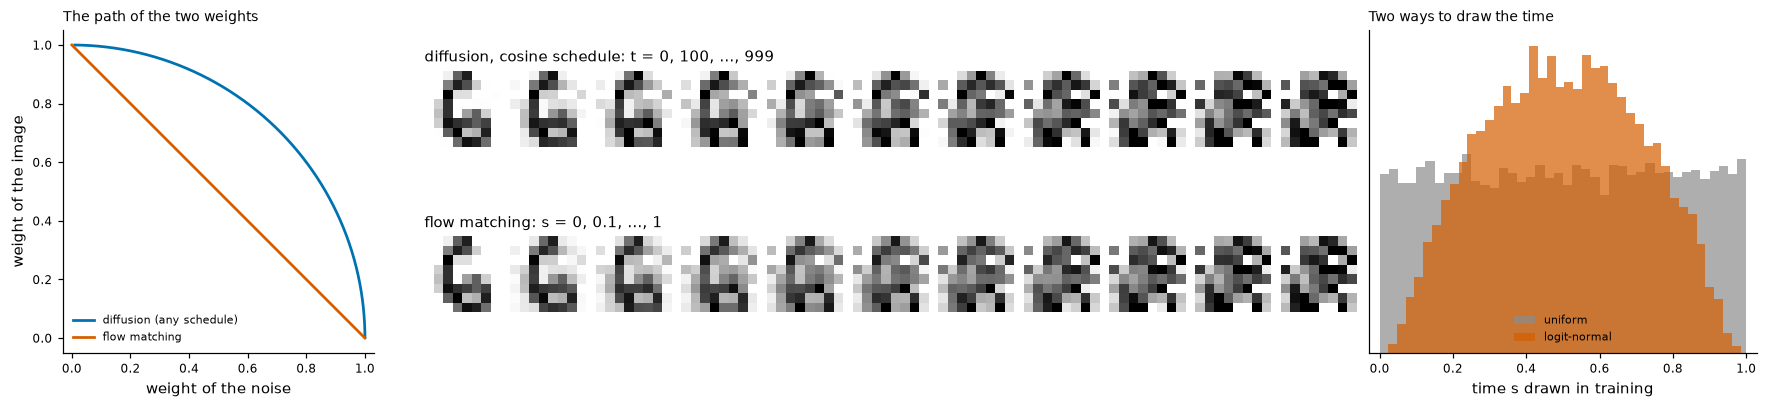

,"fd, 50 steps","fd, 20 steps","fd, 10 steps","fd, 5 steps"
"diffusion, predicts the clean image (baseline)",8.1,8.5,9.8,15.3
"the same, seed 1",8.0,8.6,9.9,15.1
"diffusion, predicts the noise",13.3,13.8,16.4,25.5
flow matching,9.2,10.1,12.1,18.4
"flow matching, logit-normal times",9.8,9.9,11.4,15.8


In [7]:
ab = D.alpha_bar("cosine"); s_grid = torch.linspace(0, 1, 200)
noise = torch.randn(64, generator=torch.Generator().manual_seed(0))
fig = plt.figure(figsize=(16, 3.6)); gs = fig.add_gridspec(2, 3, width_ratios=[1, 2.4, 1])
ax = fig.add_subplot(gs[:, 0])
ax.plot((1 - ab).sqrt(), ab.sqrt(), color=viz.BLUE, label="diffusion (any schedule)"); ax.plot(s_grid, 1 - s_grid, color=viz.VERMILION, label="flow matching")
ax.set_xlabel("weight of the noise"); ax.set_ylabel("weight of the image"); ax.set_aspect("equal"); ax.set_title("The path of the two weights", fontsize=9); ax.legend(fontsize=7, loc="lower left")
for row, (name, pairs) in enumerate((("diffusion, cosine schedule: t = 0, 100, ..., 999", [(float(ab[t].sqrt()), float((1 - ab[t]).sqrt())) for t in (0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 999)]),
                                     ("flow matching: s = 0, 0.1, ..., 1", [(1 - k / 10, k / 10) for k in range(11)]))):
    images.show_grid(torch.stack([a * Xte[0] + b * noise for a, b in pairs]), nrow=11, ax=fig.add_subplot(gs[row, 1]), title=name)
ax = fig.add_subplot(gs[:, 2])
ax.hist(torch.rand(20000).numpy(), bins=40, density=True, color=viz.GREY, alpha=0.7, label="uniform")
ax.hist(torch.sigmoid(torch.randn(20000)).numpy(), bins=40, density=True, color=viz.VERMILION, alpha=0.7, label="logit-normal")
ax.set_xlabel("time s drawn in training"); ax.set_yticks([]); ax.set_title("Two ways to draw the time", fontsize=9); ax.legend(fontsize=7, loc="lower center")
plt.show()

OBJECTIVES = {"flow matching": T.Flow("v"), "flow matching, logit-normal times": T.Flow("v", "logit-normal"), "diffusion, predicts noise": D.Diffusion("cosine", "eps")}
for name, diff in OBJECTIVES.items():
    run(name, diff)
obj_names = ["baseline", "baseline, seed 1", "diffusion, predicts noise", "flow matching", "flow matching, logit-normal times"]
STEPS = [50, 20, 10, 5]
by_steps = pd.DataFrame({n: {f"fd, {k} steps": report(n, steps=k, keep=(k == 50))["fd"] for k in STEPS} for n in obj_names}).T
by_steps.index = ["diffusion, predicts the clean image (baseline)", "the same, seed 1", "diffusion, predicts the noise", "flow matching", "flow matching, logit-normal times"]
display(by_steps.round(1))

**What happened.** All five models have the baseline architecture and 1,500 training steps.

* **Against diffusion that predicts the noise, flow matching is better at every number of sampling steps**: 9.2
  against 13.3 with 50 steps, 18.4 against 25.5 with 5. Noise prediction is what DiT used, so this is the comparison
  that [Ma et al., 2024](https://arxiv.org/abs/2401.08740) made, and the direction of their result reproduces here.
* **Against the recipe of notebook 07, it is not better**: 8.1 and 8.0 for clean-image prediction with the min-SNR
  weight, against 9.2, and 15.3 against 18.4 with 5 steps. The choices of notebook 07 had already collected what
  the straight path offers here.
* **The target matters less for a transformer than it did for the MLP.** Predicting the noise costs 5 points of FD
  here (13.3 against 8.1). In notebook 07 it cost 17 (25.2 against 8.5).
* **Logit-normal times** did not help with 50 sampling steps (9.8 against 9.2) and helped with 5 (15.8 against
  18.4). These are single runs, so the first difference may be noise.

### Are the sampling paths straighter?

The training paths of flow matching are straight by construction. The *sampling* paths need not be, because the
network learns an average velocity over all the images a noisy point could lead to. We record the path of 60
samples through the 50 steps of each sampler and measure its length divided by the distance between its two ends
(1.00 is a straight line). The animation shows the same paths in the plane of the first two principal components of
the data.

length of the sampling path divided by the distance between its ends (1.00 = straight): {'diffusion (baseline)': 1.13, 'diffusion, predicts noise': 1.13, 'flow matching': 1.04}
saved figures/nb09_paths.gif  (31 frames, 498 kB)


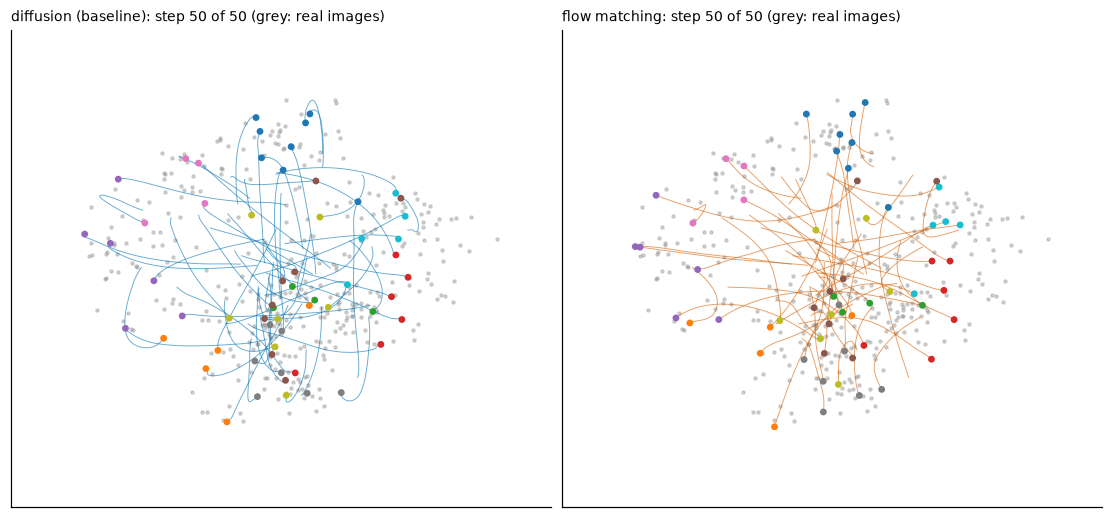

In [8]:
def paths(name, n=60, steps=50):
    r = RUNS[name]
    x, frames = r["diff"].sample(r["model"], LABELS[:n], steps=steps, record=True)
    return torch.stack([f[1] for f in frames] + [x])                           # (steps + 1, n, 64)
def straightness(p):
    return float(((p[1:] - p[:-1]).norm(dim=-1).sum(0) / (p[-1] - p[0]).norm(dim=-1)).mean())
P = {"diffusion (baseline)": paths("baseline"), "diffusion, predicts noise": paths("diffusion, predicts noise"), "flow matching": paths("flow matching")}
print("length of the sampling path divided by the distance between its ends (1.00 = straight):", {k: round(straightness(p), 2) for k, p in P.items()})

mean = Xtr.mean(0); basis = torch.linalg.svd(Xtr - mean, full_matrices=False)[2][:2]            # the first two principal directions of the data
proj = {k: (p - mean) @ basis.T for k, p in P.items()}
data2 = (Xte - mean) @ basis.T
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
shown = ["diffusion (baseline)", "flow matching"]
def frame(k):
    for ax, name in zip(axes, shown):
        ax.clear(); q = proj[name].numpy()
        ax.scatter(data2[:, 0].numpy(), data2[:, 1].numpy(), s=4, color=viz.GREY, alpha=0.35)
        ax.plot(q[:k + 1, :, 0], q[:k + 1, :, 1], color=viz.BLUE if name.startswith("diff") else viz.VERMILION, lw=0.6, alpha=0.6)
        ax.scatter(q[k, :, 0], q[k, :, 1], s=12, c=LABELS[:60], cmap="tab10", vmin=0, vmax=9, zorder=3)
        ax.set_xlim(-5, 5); ax.set_ylim(-5, 5); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{name}: step {k} of 50 (grey: real images)", fontsize=9)
viz.save_gif(fig, frame, list(range(0, 51, 2)) + [50] * 5, "nb09_paths.gif", fps=6)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6)); frame(50); plt.show()

![Sixty samples travelling from noise to data in the plane of the first two principal components: diffusion on the left, flow matching on the right](figures/nb09_paths.gif)

**What happened.** The sampling paths of flow matching are 4% longer than a straight line (1.04). Those of both
diffusion models are 13% longer (1.13). So flow matching does give straighter paths, as intended, and the paths of
diffusion were not far from straight to begin with. Part of the curvature of the diffusion paths is built in: the
variance-preserving form shrinks the sample while it removes noise.

Whether straighter paths pay off in fewer sampling steps is measured in section 9, on models trained for longer.

### Try it: choose the number of sampling steps

Static preview at the default settings {'sampling_steps': 5, 'seed': 0}. Run the notebook to get the controls.


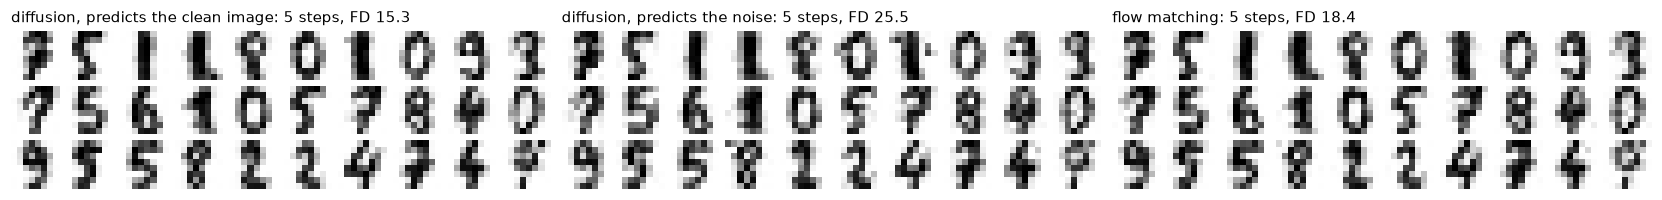

In [9]:
def steps_explorer(sampling_steps=5, seed=0):
    fig, axes = plt.subplots(1, 3, figsize=(15, 2.5))
    for ax, name, label in zip(axes, ("baseline", "diffusion, predicts noise", "flow matching"), ("diffusion, predicts the clean image", "diffusion, predicts the noise", "flow matching")):
        x = sample(name, steps=sampling_steps, seed=seed)
        images.show_grid(x[:30], nrow=10, ax=ax, title=f"{label}: {sampling_steps} steps, FD {score(x, name, sampling_steps, keep=False)['fd']:.1f}")
    plt.show()
viz.explore(steps_explorer, sampling_steps=(1, 50, 1, 5), seed=(0, 9, 1, 0))

## 6. Two ways to make training cheaper

Training a large diffusion transformer takes thousands of GPU-days, so methods that reach the same quality in fewer
steps, or make each step cheaper, matter. Two ideas from notebook 08 return here.

**Masked training** ([Zheng et al., 2023](https://arxiv.org/abs/2306.09305), [Gao et al., 2023](https://arxiv.org/abs/2303.14389)). As in the masked autoencoder, most blocks see only a random subset
of the tokens. With half of the tokens dropped, attention costs about a quarter and the rest of the block half.
Our simplified version: all blocks but the last see half of the tokens of the noisy image; before the last block
the dropped positions are filled with a learned mask token; the usual loss is applied to the visible patches, and
with a weight of 0.1 to the hidden ones. Sampling uses all tokens.

**Representation alignment**, REPA ([Yu et al., 2024](https://arxiv.org/abs/2410.06940)). The observation behind it: a diffusion transformer has to learn
what the image shows before it can denoise it, and it learns this slowly, as a by-product. A pretrained encoder
already knows. So add a second loss that pulls the denoiser's hidden tokens, after an early block, towards the
patch features that a frozen encoder computes for the **clean** image. We use the contrastive encoder of notebook
08 (it is loaded from that notebook's checkpoint, or retrained if the checkpoint is missing). The tokens after the
second block go through a small MLP, and the loss is their cosine similarity with the encoder's 16 patch features,
with weight 0.5. The encoder is used in training only.

Both are compared with the baseline, at equal steps and at equal time.

,milliseconds per step,fd at step 250,fd at step 500,fd at step 750,fd at step 1000,fd at step 1250,fd at step 1500
baseline,37.6,32.6,12.6,9.6,8.2,7.6,8.1
masked training,35.8,34.2,15.7,14.3,12.5,12.1,11.7
REPA,55.4,18.7,8.5,6.5,5.7,6.0,6.1


training time to reach each measurement, in seconds (steps x measured time per step):


,step 250,step 500,step 750,step 1000,step 1250,step 1500
baseline,9.0,19.0,28.0,38.0,47.0,56.0
masked training,9.0,18.0,27.0,36.0,45.0,54.0
REPA,14.0,28.0,42.0,55.0,69.0,83.0


,parameters (k),compute per pass (M),training seconds,fd,precision,coverage,judge reads the requested digit,fd with 10 steps
baseline,247.0,2.4,49.0,8.1,0.91,0.93,0.96,9.8
"baseline, seed 1",247.0,2.4,44.0,8.0,0.93,0.90,0.96,9.9
masked training,247.0,2.4,58.0,11.7,0.91,0.85,0.94,14.8
REPA,247.0,2.4,83.0,6.1,0.94,0.92,0.96,8.0


,1 label per digit,5 labels per digit,20 labels per digit
pixels of the noised image (the denoiser's input),0.440,0.683,0.778
"hidden tokens, baseline",0.233,0.432,0.647
"hidden tokens, REPA",0.412,0.608,0.755
"the pretrained encoder, on the noised image",0.446,0.663,0.759
"the pretrained encoder, on the clean image",0.733,0.876,0.927


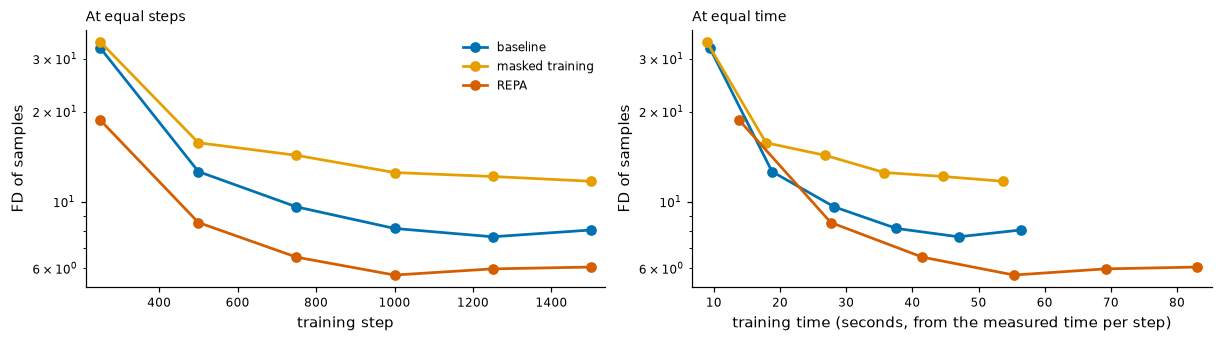

In [10]:
base = D.Diffusion(**BASE)
encoder = V.get_vision_encoder()
def step_ms(diff, n=40, **arch):
    # milliseconds per training step (batch of 128), measured over n steps
    set_seed(0); net = T.DiT(**arch); opt = torch.optim.AdamW(net.parameters(), 2e-3); t0 = time.time()
    for _ in range(n):
        idx = torch.randint(0, len(Xtr), (128,)); loss = diff.loss(net, Xtr[idx], ytr[idx]); opt.zero_grad(); loss.backward(); opt.step()
    return 1000 * (time.time() - t0) / n

run("masked training", T.Masked(base, 0.5), sampler=base, track=True)
run("REPA", T.Repa(base, encoder, 0.5), sampler=base, track=True, hidden_layer=1, align_dim=64)
ms = {"baseline": step_ms(base), "masked training": step_ms(T.Masked(base, 0.5)), "REPA": step_ms(T.Repa(base, encoder, 0.5), hidden_layer=1, align_dim=64)}
acc = pd.DataFrame({n: RUNS[n]["track"] for n in ms}).T
acc.columns = [f"fd at step {c}" for c in acc.columns]; acc.insert(0, "milliseconds per step", pd.Series(ms))
display(acc.round(1))
print("training time to reach each measurement, in seconds (steps x measured time per step):")
display(pd.DataFrame({n: {f"step {s}": s * ms[n] / 1000 for s in RUNS[n]["track"].index} for n in ms}).T.round(0))
display(summary(["baseline", "baseline, seed 1", "masked training", "REPA"]))

# What do the hidden tokens know? A linear probe on the mean hidden token after block 2, for lightly noised images (30% of the way to noise).
level = 0.3; t_probe = torch.full((1,), int(level * (D.T - 1)))
def noised(Z):
    return base.q_sample(Z, t_probe.expand(len(Z)), torch.randn(Z.shape, generator=torch.Generator().manual_seed(0)))
def hidden_of(name):
    RUNS[name]["model"].hidden_layer = 1
    return lambda Z: T.hidden_features(RUNS[name]["model"], Z, None, base, level)
feats = {"pixels of the noised image (the denoiser's input)": noised, "hidden tokens, baseline": hidden_of("baseline"), "hidden tokens, REPA": hidden_of("REPA"),
         "the pretrained encoder, on the noised image": lambda Z: encoder.features(noised(Z)), "the pretrained encoder, on the clean image": encoder.features}
probes = pd.DataFrame({n: {f"{k} label{'s' if k > 1 else ''} per digit": V.probe(f, Xtr, ytr, Xte, yte, per_class=k) for k in (1, 5, 20)} for n, f in feats.items()}).T
display(probes.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for n, col in (("baseline", viz.BLUE), ("masked training", viz.ORANGE), ("REPA", viz.VERMILION)):
    tr = RUNS[n]["track"]
    axes[0].plot(tr.index, tr.values, "o-", color=col, label=n); axes[1].plot(tr.index * ms[n] / 1000, tr.values, "o-", color=col, label=n)
axes[0].set_xlabel("training step"); axes[1].set_xlabel("training time (seconds, from the measured time per step)")
for ax in axes:
    ax.set_yscale("log"); ax.set_ylabel("FD of samples")
axes[0].set_title("At equal steps", fontsize=9); axes[1].set_title("At equal time", fontsize=9); axes[0].legend(fontsize=8, loc="upper right")
plt.show()

**What happened.**

* **Masked training gave nothing here.** A step was barely cheaper (35.8 ms against 37.6), and the samples were
  worse at every measurement: FD 11.7 against 8.1 at the end. The saving is small because with 16 tokens attention is a small
  part of the cost, and because our last block still sees every position. Dropping half of the 256 or more tokens of
  a large model saves far more. And half of 16 tokens leaves the model eight patches of a digit to learn from.
* **REPA made training faster and better.** FD 8.5 against 12.6 at step 500, and 6.1 against 8.1 at the end. A step
  costs about half as much again (55.4 ms against 37.6), because the frozen encoder also runs on every batch. The
  second table converts steps to time. After about 28 seconds REPA is at 8.5 (step 500) and the baseline at 9.6
  (step 750). After about 55 seconds REPA is at 5.7 (step 1,000) and the baseline at 8.1 (step 1,500). So it is
  ahead at equal time too, by less than at equal steps. The times per step are measured over 40 steps and vary
  from one execution of the notebook to the next; in an earlier execution REPA cost about 30% more per step.
* **What alignment changed inside the model** (third table, a linear probe on the mean hidden token after block 2,
  for lightly noised images). The baseline's hidden tokens say little about which digit is shown: 0.23, 0.43 and
  0.65 with 1, 5 and 20 labels per digit. With REPA: 0.41, 0.61 and 0.76, close to what the encoder itself gives on
  the same noised images (0.45, 0.66, 0.76). That is the mechanism [Yu et al., 2024](https://arxiv.org/abs/2410.06940) describe: the denoiser is handed a
  representation that it would otherwise have to find by itself.
* Two cautions. The probe averages over the 16 tokens and so discards where things are; raw noised pixels, which
  keep that, score higher than all hidden tokens (0.44, 0.68, 0.78). And section 8 tests whether the gain lasts.

## 7. Inside the model: what attention does during sampling

A transformer denoiser can be inspected in a way an MLP cannot: for every patch we can read which other patches
its attention draws on. We sample 64 images with the baseline, record the attention of each block at each of the 50
steps, and compute the **mean attention distance**: how far away, in patches, the attended patches are on average.
If attention were spread evenly over the 16 patches, the distance would be the mean distance between two patches of
the grid, shown as a dotted line.

,block 1,block 2,block 3
timestep,,,
999,1.92,1.75,1.81
754,1.91,1.74,1.81
510,1.90,1.70,1.79
265,1.89,1.71,1.80
0,1.93,1.89,1.91


evenly spread attention would give 2.01


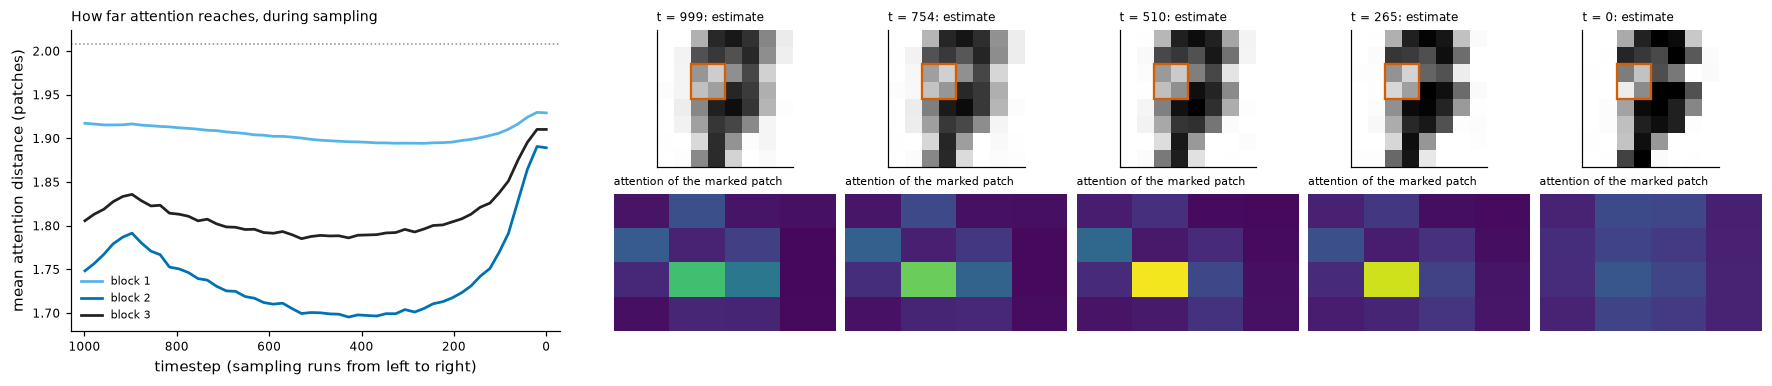

In [11]:
r = RUNS["baseline"]; model, diff = r["model"], r["diff"]
_, frames = diff.sample(model, LABELS[:64], steps=50, record=True)
rows_, cols_ = T.grid_positions(4); dist = ((rows_[:, None] - rows_[None]) ** 2 + (cols_[:, None] - cols_[None]) ** 2).sqrt()       # distance between patches, in patches
ATT = {(k, b): model.attention(x, torch.full((64,), t), LABELS[:64], block=b) for k, (t, x, x0) in enumerate(frames) for b in range(3)}
mad = pd.DataFrame({f"block {b + 1}": [float((ATT[(k, b)] * dist).sum(-1).mean()) for k in range(50)] for b in range(3)}, index=[f[0] for f in frames])
mad.index.name = "timestep"
display(mad.iloc[[0, 12, 24, 36, 49]].round(2))
print(f"evenly spread attention would give {float(dist.mean()):.2f}")

fig = plt.figure(figsize=(16, 3.4)); gs = fig.add_gridspec(2, 7, width_ratios=[2.2, 0.2, 1, 1, 1, 1, 1])
ax = fig.add_subplot(gs[:, 0])
for b, col in enumerate((viz.SKY, viz.BLUE, viz.BLACK)):
    ax.plot(mad.index, mad[f"block {b + 1}"], color=col, label=f"block {b + 1}")
ax.axhline(float(dist.mean()), color=viz.GREY, ls=":", lw=1); ax.invert_xaxis(); ax.set_xlabel("timestep (sampling runs from left to right)"); ax.set_ylabel("mean attention distance (patches)")
ax.set_title("How far attention reaches, during sampling", fontsize=9); ax.legend(fontsize=7, loc="lower left")
query = 5                                                                              # the patch in row 2, column 2
for j, k in enumerate((0, 12, 24, 36, 49)):
    t, x, x0 = frames[k]
    a1 = fig.add_subplot(gs[0, j + 2]); a1.imshow(x0[0].view(8, 8).clamp(-1, 1), cmap="gray_r", vmin=-1, vmax=1); a1.set_xticks([]); a1.set_yticks([]); a1.set_title(f"t = {t}: estimate", fontsize=8)
    a1.add_patch(plt.Rectangle((2 * (query % 4) - 0.5, 2 * (query // 4) - 0.5), 2, 2, fill=False, ec=viz.VERMILION, lw=1.5))
    a2 = fig.add_subplot(gs[1, j + 2]); viz.heat(a2, ATT[(k, 2)][0, query].view(4, 4).numpy(), cmap="viridis", vmin=0, vmax=0.4); a2.set_xticks([]); a2.set_yticks([])
    a2.set_title("attention of the marked patch", fontsize=7)
plt.show()

**Reading the figure.**

* **Attention is only a little more local than even.** The mean distance is between 1.70 and 1.93 patches in every
  block and at every step, against 2.01 for attention spread evenly. Block 2 is the most local, and block 1 the
  least.
* **It changes little during sampling until the last steps.** There the distance rises in all three blocks, to
  1.89 to 1.93: with almost no noise left, attention spreads out.
* **Single patches have particular partners.** In the example, the marked patch gives most of its attention in
  block 3 to the patch directly below it, and much less to its other neighbours. The explorer below shows this for
  any patch and step.

A grid of 4×4 tokens is too small for strong statements about local and global attention. What the section shows
is that the question can be asked of a transformer at all, with nothing more than its attention weights.

### Try it: step through sampling and read the attention

Static preview at the default settings {'step': 25, 'patch_row': 2, 'patch_column': 2, 'image': 0, 'block': 3}. Run the notebook to get the controls.


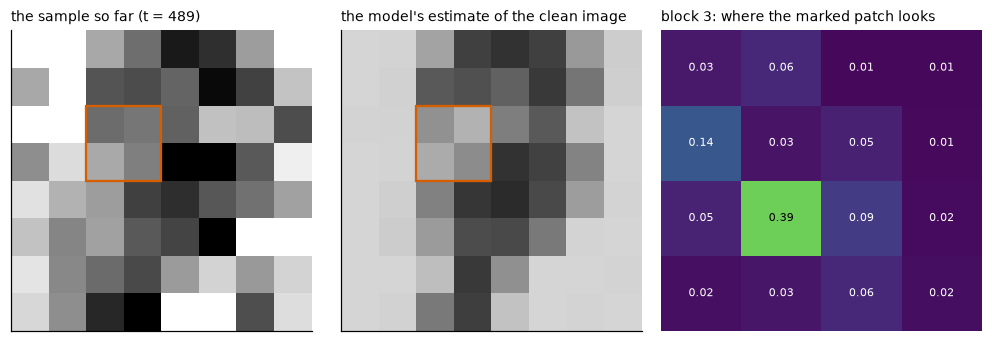

In [12]:
def attention_explorer(step=25, patch_row=2, patch_column=2, image=0, block=3):
    t, x, x0 = frames[step]; q = (patch_row - 1) * 4 + (patch_column - 1)
    fig, axes = plt.subplots(1, 3, figsize=(9, 3))
    for ax, im, title in ((axes[0], x[image], f"the sample so far (t = {t})"), (axes[1], x0[image].clamp(-1, 1), "the model's estimate of the clean image")):
        ax.imshow(im.view(8, 8), cmap="gray_r", vmin=-1.5, vmax=1.5); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
        ax.add_patch(plt.Rectangle((2 * (patch_column - 1) - 0.5, 2 * (patch_row - 1) - 0.5), 2, 2, fill=False, ec=viz.VERMILION, lw=1.5))
    viz.heat(axes[2], ATT[(step, block - 1)][image, q].view(4, 4).numpy(), annotate=True, fmt="{:.2f}", cmap="viridis", vmin=0, vmax=0.5); axes[2].set_xticks([]); axes[2].set_yticks([])
    axes[2].set_title(f"block {block}: where the marked patch looks", fontsize=9)
    plt.show()
viz.explore(attention_explorer, step=(0, 49, 1, 25), patch_row=(1, 4, 1, 2), patch_column=(1, 4, 1, 2), image=(0, 63, 1, 0), block=(1, 3, 1, 3))

## 8. The base diffusion transformer

We combine the choices that measured best and train for 3,000 steps: the baseline architecture (16 tokens, adaLN-Zero)
with the position scheme that did best in section 4, trained with the objective that did best in section 5. We keep 16
tokens although 4 tokens scored better in section 2, so that the model has a grid of patches worth studying in
notebook 10 and in the post-training series. Three runs:

* the **base model**;
* the same with **REPA**, to see whether the gain of section 6 survives longer training;
* the same architecture trained with **flow matching**, to see whether the gap of section 5 survives it.

The first is saved as `checkpoints/base_dit.pt`. It gets the memorisation checks of notebook 07.

,parameters (k),compute per pass (M),training seconds,fd,precision,coverage,judge reads the requested digit,fd with 10 steps
base DiT,246.0,2.4,134.0,5.5,0.96,0.92,0.96,6.6
base DiT + REPA,246.0,2.4,160.0,5.6,0.96,0.95,0.97,7.1
"base DiT, flow matching",246.0,2.4,140.0,5.8,0.96,0.92,0.96,8.0


FD during training:


,500,1000,1500,2000,2500,3000
base DiT,8.7,5.9,6.1,5.8,5.8,5.5
base DiT + REPA,8.1,6.0,5.9,6.2,6.2,5.6
"base DiT, flow matching",14.8,8.5,7.2,6.2,6.1,5.8


base DiT with 10 sampling steps: FD 6.6; with guidance scale 1: FD 12.5, judge reads the requested digit 1.00
held-out images: median distance to the nearest training image 2.07


,nn_ratio,median distance to nearest training image,samples within 0.5 of a training image,"training / held-out error, least noise"
baseline,0.97,2.36,0.0,0.94
base DiT,0.96,2.26,0.0,0.92
base DiT + REPA,0.95,2.15,0.0,0.91
"base DiT, flow matching",0.97,2.28,0.0,NaN


saved checkpoints/base_dit.pt


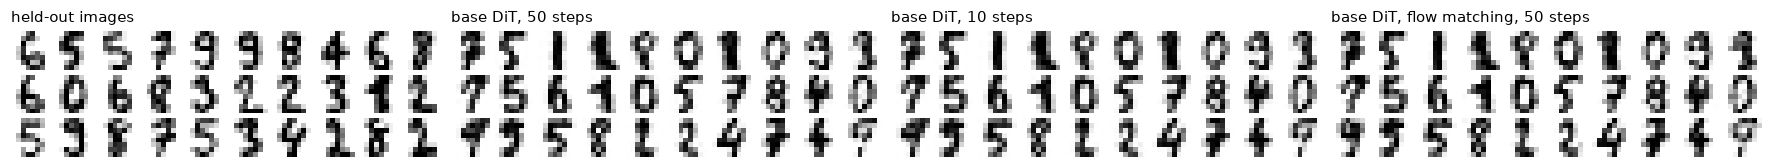

In [13]:
ARCH = dict(pos="sincos")
run("base DiT", steps=3000, track=True, **ARCH)
run("base DiT + REPA", T.Repa(base, encoder, 0.5), sampler=base, steps=3000, track=True, hidden_layer=1, align_dim=64, **ARCH)
run("base DiT, flow matching", T.Flow("v"), steps=3000, track=True, **ARCH)
finals = ["base DiT", "base DiT + REPA", "base DiT, flow matching"]
display(summary(finals))
print("FD during training:")
display(pd.DataFrame({n: RUNS[n]["track"] for n in finals}).T.iloc[:, 1::2].round(1))
for n in finals[:1]:
    report(n, row=n + ", 10 steps", steps=10); report(n, row=n + ", guidance 1", w=1.0)
print(f"base DiT with 10 sampling steps: FD {ROWS['base DiT, 10 steps']['fd']:.1f}; with guidance scale 1: FD {ROWS['base DiT, guidance 1']['fd']:.1f}, judge reads the requested digit {ROWS['base DiT, guidance 1']['judge_acc']:.2f}")

def memorisation(name):
    r = RUNS[name]; x = sample(name); d = torch.cdist(x, Xtr).min(1).values
    out = {"nn_ratio": ROWS[name]["nn_ratio"], "median distance to nearest training image": float(d.median()), "samples within 0.5 of a training image": int((d < 0.5).sum())}
    if isinstance(r["diff"], D.Diffusion):
        e_tr = r["diff"].error_by_time(r["model"], Xtr[:N], ytr[:N])[1]; e_te = r["diff"].error_by_time(r["model"], Xte, yte)[1]
        out["training / held-out error, least noise"] = e_tr[0] / e_te[0]
    return out
print(f"held-out images: median distance to the nearest training image {float(torch.cdist(Xte, Xtr).min(1).values.median()):.2f}")
display(pd.DataFrame({n: memorisation(n) for n in ["baseline"] + finals}).T.round(2))
torch.save(dict(state=RUNS["base DiT"]["model"].state_dict(), config=dict(d=64, depth=3, heads=4, patch=2, cond="adaln-zero", **ARCH), objective=BASE), os.path.join(CKPT_DIR, "base_dit.pt"))
print("saved checkpoints/base_dit.pt")
fig, axes = plt.subplots(1, 4, figsize=(16, 2.5))
for ax, (title, x) in zip(axes, (("held-out images", Xte), ("base DiT, 50 steps", sample("base DiT")), ("base DiT, 10 steps", sample("base DiT", steps=10)), ("base DiT, flow matching, 50 steps", sample("base DiT, flow matching")))):
    images.show_grid(x[:30], nrow=10, ax=ax, title=title)
plt.show()

**What happened.**

* **The base model reaches the FD of real data.** FD 5.5, precision 0.96, coverage 0.92. Real data score
  5.4, 0.96 and 0.96. With 10 sampling steps: 6.6. Coverage is the remaining gap.
* **Better than the MLP, with a quarter of the parameters and far less memorisation.** The final MLP of notebook 07
  had 1.1 million parameters and scored 7.0. Its denoising error on training images was 0.55 of that on held-out
  images at the lowest noise level, and its nn_ratio was 0.87. For the base DiT (246,000 parameters) the ratio is
  0.92 and the nn_ratio 0.96, and its samples are slightly further from the nearest training image (2.26) than
  held-out images are (2.07). In notebook 07 a lower FD came together with leaning on the training set. Here it does
  not. A possible reason, not tested: the same weights process all 16 patches, which makes storing whole images
  harder than it is for an MLP.
* **Time.** It trains in a little over two minutes (134 s, including its measurements during training), where the
  MLP of notebook 07 took 25 seconds.
* **REPA no longer helps**: 5.6 against 5.5 after 3,000 steps, and the two are level from step 1,000 on. The gain of
  section 6 did not carry over. The base model differs from the model of section 6 in its positions as well as in
  its training time, and the table shows that the positions are what matters: at step 1,500, with sinusoidal
  positions, REPA gives 5.9 against 6.1. In sections 4 and 6, sinusoidal positions alone and REPA alone each took
  the learned-position baseline from 8.1 to about 6. The two gains do not add. An interpretation, not tested: the
  encoder's patch features say where each patch is, since the encoder has position vectors of its own. So part of
  what alignment taught the model of section 6 was the layout of the grid, which sinusoidal positions supply for
  nothing. [Yu et al., 2024](https://arxiv.org/abs/2410.06940) report large gains with a strong encoder on ImageNet. Our encoder is tiny, and notebook 08
  showed that its features are barely better than pixels.
* **Flow matching converges more slowly and ends close**: 14.8 against 8.7 at step 500, 7.2 against 6.1 at step
  1,500, 5.8 against 5.5 at the end.
* **Guidance now hurts.** At a guidance scale of 1 the judge reads every sample as the requested digit, and FD rises
  from 5.5 to 12.5. A model this close to the data has nothing for guidance to repair, and pays for it in diversity.

## 9. Scorecard

,fd,precision,coverage,nn_ratio,judge_acc,nfe
model,,,,,,
"MLP denoiser, 1,500 steps",11.23,0.93,0.93,0.93,0.93,50
"DiT baseline, 1,500 steps",8.05,0.91,0.93,0.97,0.96,50
"DiT, width 96 and 4 blocks, 1,500 steps",6.31,0.95,0.92,0.95,0.98,50
"DiT, flow matching, 1,500 steps",9.17,0.91,0.87,0.97,0.96,50
"DiT with REPA, 1,500 steps",6.06,0.94,0.92,0.96,0.96,50
"base DiT, 3,000 steps",5.50,0.96,0.92,0.96,0.96,50
"base DiT, 10 sampling steps",6.59,0.97,0.94,0.95,0.98,10
"base DiT with REPA, 3,000 steps",5.61,0.96,0.95,0.95,0.97,50
"base DiT, flow matching, 3,000 steps",5.79,0.96,0.92,0.97,0.96,50


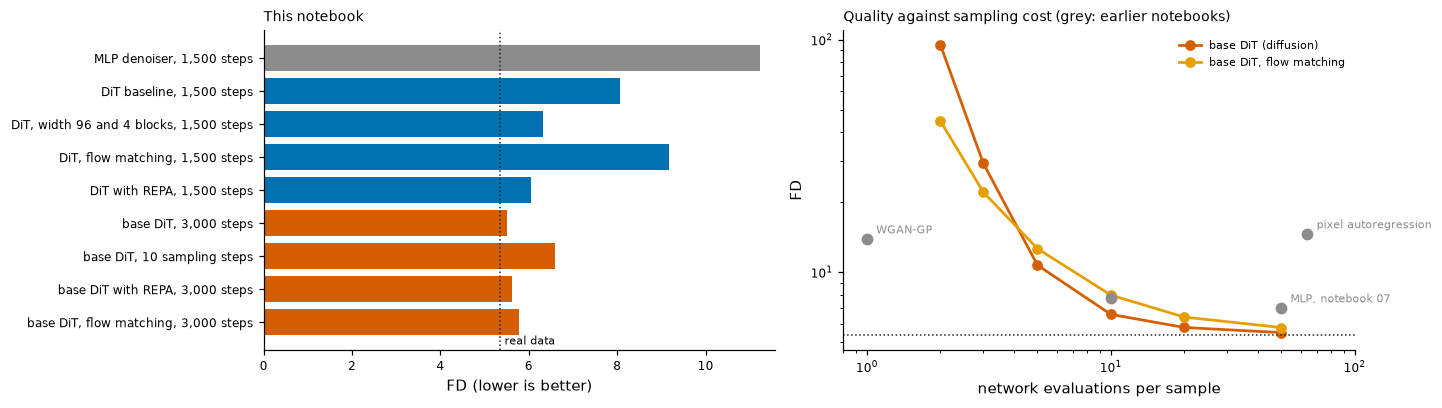

FD by number of sampling steps: {'base DiT': {2: 95.1, 3: 29.4, 5: 10.7, 10: 6.6, 20: 5.8, 50: 5.5}, 'base DiT, flow matching': {2: 44.7, 3: 22.1, 5: 12.6, 10: 8.0, 20: 6.4, 50: 5.8}}


In [14]:
names = {"MLP of notebook 07": "MLP denoiser, 1,500 steps", "baseline": "DiT baseline, 1,500 steps", "width 96, 4 blocks": "DiT, width 96 and 4 blocks, 1,500 steps",
         "flow matching": "DiT, flow matching, 1,500 steps", "REPA": "DiT with REPA, 1,500 steps", "base DiT": "base DiT, 3,000 steps", "base DiT, 10 steps": "base DiT, 10 sampling steps",
         "base DiT + REPA": "base DiT with REPA, 3,000 steps", "base DiT, flow matching": "base DiT, flow matching, 3,000 steps"}
rows = [dict(model=label, family="image", **{k: ROWS[n].get(k) for k in ("fd", "precision", "coverage", "nn_ratio", "judge_acc", "nfe")}) for n, label in names.items()]
card_table = pd.DataFrame(rows).set_index("model")[["fd", "precision", "coverage", "nn_ratio", "judge_acc", "nfe"]]
display(card_table.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
ax = axes[0]
labels_ = list(names.values())[::-1]
ax.barh(labels_, [card_table.loc[l, "fd"] for l in labels_], color=[viz.GREY if l.startswith("MLP") else viz.VERMILION if "base DiT" in l else viz.BLUE for l in labels_])
ax.axvline(earlier.loc["real data", "fd"].iloc[0], color=viz.BLACK, ls=":", lw=1); ax.text(earlier.loc["real data", "fd"].iloc[0] + 0.1, -0.4, "real data", fontsize=7, va="top")
ax.set_xlabel("FD (lower is better)"); ax.set_title("This notebook", fontsize=9)
ax = axes[1]
steps_ = [2, 3, 5, 10, 20, 50]
for n, col, label in (("base DiT", viz.VERMILION, "base DiT (diffusion)"), ("base DiT, flow matching", viz.ORANGE, "base DiT, flow matching")):
    ax.plot(steps_, [report(n, steps=k, keep=False)["fd"] for k in steps_], "o-", color=col, label=label)
for n, label in (("WGAN-GP, median of 3 seeds", "WGAN-GP"), ("pixel autoregression, median of 3 seeds", "pixel autoregression"), ("final recipe", "MLP, notebook 07"), ("final recipe, 10 steps", None)):
    ax.scatter(earlier.loc[n, "nfe"], earlier.loc[n, "fd"], s=45, color=viz.GREY, zorder=3)
    if label:
        ax.annotate(label, (earlier.loc[n, "nfe"], earlier.loc[n, "fd"]), textcoords="offset points", xytext=(6, 4), fontsize=7, color=viz.GREY)
ax.axhline(earlier.loc["real data", "fd"].iloc[0], color=viz.BLACK, ls=":", lw=1)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.8, 100); ax.set_xlabel("network evaluations per sample"); ax.set_ylabel("FD"); ax.set_title("Quality against sampling cost (grey: earlier notebooks)", fontsize=9); ax.legend(fontsize=7, loc="upper right")
plt.show()
print("FD by number of sampling steps:", {n: {k: round(report(n, steps=k, keep=False)["fd"], 1) for k in steps_} for n in ("base DiT", "base DiT, flow matching")})
metrics.append_rows(rows, "09_dit");

**Reading the scorecard.**

* **Left.** Every diffusion transformer in the panel is ahead of the MLP trained for the same number of steps,
  and the three models trained for 3,000 steps are within half a point of real data.
* **Right: do straighter paths save sampling steps?** Only where neither model is usable. With 2 and 3 steps flow
  matching is better (FD 44.7 against 95.1, and 22.1 against 29.4). From 5 steps on the diffusion model is better
  (10.7 against 12.6 with 5 steps, 6.6 against 8.0 with 10). Challenge 1 shows that a better solver helps flow
  matching more than a straighter path did.
* **Against the earlier families.** With 5 network evaluations the base DiT (10.7) is ahead of the WGAN-GP with
  one (13.8) and of the pixel model with 64 (14.6). With 10 it is at 6.6.

Three statements of the literature did not reproduce at this scale, and each has a plausible reason given above:
smaller patches are better (section 2), flow matching beats diffusion (true against noise prediction only, section
5), and representation alignment speeds up training (true only with learned positions, section 8). Each is a
statement about large models on natural images, and this notebook neither confirms nor refutes it there.

**What is left.** The base model needs ten or more network evaluations per image, it follows a label and not a
text, and nobody has told it what a *good* image is beyond resembling the training set. Reducing the number of
steps, adapting to new data, and aligning with preferences are the subject of the post-training series, which
starts from a checkpoint like the one saved above. Before that, notebook 10 puts the objectives of this series side
by side on one backbone.

## 10. Design choices: what changed, and the recipes of well-known models

| Choice | Earlier | Moved to | Why | Measured here |
|---|---|---|---|---|
| Backbone | Convolutional U-Net ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)) | Transformer on patches ([Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748), [Bao et al., 2022](https://arxiv.org/abs/2209.12152)) | One architecture for every modality; quality follows compute | DiT 8.1 against MLP 11.2 at 1,500 steps. Base DiT 5.5 with 246k parameters against 7.0 for an MLP with 1.1M, and less memorisation (error ratio 0.92 against 0.55) |
| Number of tokens | Fixed by the U-Net | Chosen by the patch size; smaller patches when compute allows ([Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748)) | More tokens, more compute, better samples | The opposite at 1,500 steps: 4 tokens 6.3, 16 tokens 8.1, 64 tokens 13.4. Width and depth did follow compute: 14.6, 8.1, 6.3 |
| Conditioning route | Concatenation or cross-attention | adaLN-Zero for timestep and class ([Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748)); joint attention over text and image tokens ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)) | Cheap, and stable at initialisation | adaLN-Zero 8.1, adaLN without the gate 7.8, in-context 10.0, cross-attention 11.5 |
| Positions | Learned or fixed sinusoidal | 2-D RoPE ([Su et al., 2021](https://arxiv.org/abs/2104.09864), [Lu et al., 2024](https://arxiv.org/abs/2402.12376)) | Carries over to other resolutions | Fixed sinusoidal 6.4, learned 8.1, 2-D RoPE 7.9, none 141.6. Other resolutions not tested |
| Path from data to noise | Curved (variance-preserving diffusion) | Straight: flow matching ([Lipman et al., 2022](https://arxiv.org/abs/2210.02747), [Liu et al., 2022](https://arxiv.org/abs/2209.03003), [Ma et al., 2024](https://arxiv.org/abs/2401.08740)) | Simpler; fewer sampling steps | Flow matching 9.2: better than noise-predicting diffusion (13.3), not better than clean-image diffusion (8.1). Paths 1.04 against 1.13 of a straight line; ahead only with 2 to 3 sampling steps |
| Time drawn in training | Uniform | Logit-normal ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)) | The middle of the path is the hard part | 50 sampling steps: 9.8 against 9.2 for uniform. 5 steps: 15.8 against 18.4. One run each |
| Cost of a training step | All tokens | A subset of the tokens ([Zheng et al., 2023](https://arxiv.org/abs/2306.09305), [Gao et al., 2023](https://arxiv.org/abs/2303.14389)) | Attention cost falls with the square of the token count | Half of 16 tokens: a step about 5% cheaper, FD 11.7 against 8.1 |
| What the hidden tokens learn | Whatever denoising teaches | Aligned with a pretrained encoder ([Yu et al., 2024](https://arxiv.org/abs/2410.06940)) | Faster convergence | Learned positions, 1,500 steps: 6.1 against 8.1. Sinusoidal positions, 3,000 steps: 5.6 against 5.5 |

**The recipes of some well-known diffusion transformers**, as published.

| Model | Tokens | Conditioning | Positions | Objective |
|---|---|---|---|---|
| DiT ([Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748)) | Patches of the latent code of an autoencoder | adaLN-Zero (class, timestep) | Fixed sinusoidal | Diffusion, predicts the noise |
| U-ViT ([Bao et al., 2022](https://arxiv.org/abs/2209.12152)) | The same, with long skip connections between blocks | In-context tokens | Learned | Diffusion, predicts the noise |
| SiT ([Ma et al., 2024](https://arxiv.org/abs/2401.08740)) | As DiT | As DiT | As DiT | Flow matching and related interpolants |
| Stable Diffusion 3 ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)) | Latent patches and text tokens in one sequence, with separate weights for the two | Joint attention, plus adaLN for timestep and pooled text | Fixed sinusoidal | Rectified flow, logit-normal times |
| FiT ([Lu et al., 2024](https://arxiv.org/abs/2402.12376)) | Latent patches, any resolution | As DiT | 2-D RoPE | As SiT |

## Challenge Problem 1: A second-order sampler for flow matching

Euler's method uses the velocity at the start of each step. Heun's method (used by EDM in notebook 07) takes a trial Euler step, evaluates the
velocity again at the end point, and repeats the step with the average of the two velocities. It costs two network evaluations per step, except for the
last step, where the end point is $s = 0$. Implement it for the flow-matching model `RUNS["base DiT, flow matching"]` using `flow.predict(model, x, s,
labels)`, and compare it with Euler at an equal number of network evaluations (5, 9, 19 and 39). Does the second-order sampler pay for itself?

In [15]:
# Start your code here

### Challenge Problem 1 Solution

In [16]:
flow, fm = RUNS["base DiT, flow matching"]["diff"], RUNS["base DiT, flow matching"]["model"]
@torch.no_grad()
def heun(steps, seed=0):
    x = torch.randn(N, 64, generator=torch.Generator().manual_seed(seed)); grid = torch.linspace(1, 0, steps + 1)
    for i in range(steps):
        s, s_next = float(grid[i]), float(grid[i + 1])
        v = flow.predict(fm, x, s, LABELS); trial = x - (s - s_next) * v
        x = trial if s_next == 0 else x - (s - s_next) * (v + flow.predict(fm, trial, s_next, LABELS)) / 2
    return x
out = {}
for steps in (3, 5, 10, 20):
    nfe = 2 * steps - 1
    out[nfe] = {"Heun": score(heun(steps), "heun", nfe, keep=False)["fd"], "Euler, same number of evaluations": score(flow.sample(fm, LABELS, steps=nfe), "euler", nfe, keep=False)["fd"]}
t = pd.DataFrame(out).T; t.index.name = "network evaluations"
display(t.round(1))
# Read the table. With 5 network evaluations Euler is better (12.6 against 13.8): a few more first-order steps beat
# fewer second-order ones. From 9 evaluations on Heun is better at equal cost: 7.6 against 8.5, 5.7 against 6.5, and
# 5.4 against 5.9. Heun with 19 evaluations (5.7) matches Euler with 50 (5.8 in section 8).
# So the solver was worth more than the path. Making the path straight changed little from 5 steps on (section 9);
# following a slightly curved path with a second-order method cut the number of evaluations by more than half.
# This is why sampler papers (notebook 07, section 3) moved faster than training papers: they need no retraining.

,Heun,"Euler, same number of evaluations"
network evaluations,,
5,13.8,12.6
9,7.6,8.5
19,5.7,6.5
39,5.4,5.9


## Challenge Problem 2: What the zero-initialised gates became

Every block of the base model multiplies the output of its attention layer and of its feed-forward layer by a gate that was zero at
initialisation and is computed from the timestep and the label. Read the gates of the trained model: for the label 3 and timesteps 0, 50, ..., 950,
compute the mean absolute value of each block's two gates and plot them against the timestep. Which blocks are switched on most strongly, and at which
noise levels?

In [17]:
# Start your code here

### Challenge Problem 2 Solution

,"block 1, attention","block 1, feed-forward","block 2, attention","block 2, feed-forward","block 3, attention","block 3, feed-forward"
timestep,,,,,,
0,0.14,0.35,0.21,0.24,0.16,0.24
250,0.28,0.49,0.39,0.43,0.47,0.57
500,0.40,0.63,0.51,0.57,0.68,0.81
750,0.50,0.80,0.58,0.70,0.82,0.98
950,0.62,1.03,0.68,0.88,0.97,1.14


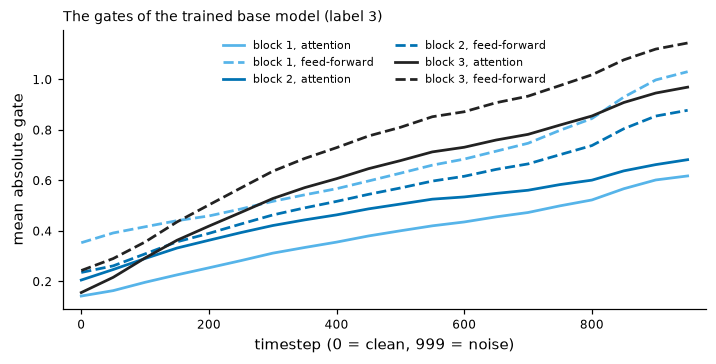

In [18]:
net = RUNS["base DiT"]["model"]; ts = torch.arange(0, 1000, 50)
with torch.no_grad():
    e = net.temb(D.timestep_embedding(ts)) + net.cemb(torch.full((len(ts),), 3))
    gates = {}
    for b, blk in enumerate(net.blocks):
        parts = blk.ada(e).chunk(6, -1)
        gates[f"block {b + 1}, attention"] = parts[2].abs().mean(-1).numpy(); gates[f"block {b + 1}, feed-forward"] = parts[5].abs().mean(-1).numpy()
g = pd.DataFrame(gates, index=pd.Index(ts.numpy(), name="timestep"))
display(g.iloc[[0, 5, 10, 15, 19]].round(2))
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for (name, col), ls in zip(((f"block {b + 1}, {kind}", c) for b, c in enumerate((viz.SKY, viz.BLUE, viz.BLACK)) for kind in ("attention", "feed-forward")), ["-", "--"] * 3):
    ax.plot(g.index, g[name], color=col, ls=ls, label=name)
ax.set_xlabel("timestep (0 = clean, 999 = noise)"); ax.set_ylabel("mean absolute gate"); ax.set_title("The gates of the trained base model (label 3)", fontsize=9); ax.legend(fontsize=7, ncol=2, loc="upper center")
plt.show()
# Read the table and the figure. Every gate grows with the noise level. At timestep 0 the six gates lie between 0.14
# and 0.35, and at timestep 950 between 0.62 and 1.14. The last block changes most: its attention gate goes from
# 0.16 to 0.97. In every block the gate of the feed-forward layer is larger than that of the attention layer.
# A reading, not a test: the model predicts the clean image. At low noise the input is almost the answer and the
# blocks have little to change, so they are nearly switched off. At high noise the image has to be constructed, and
# the blocks are fully on. The gate is one of three things a block receives from the condition (with a scale and a
# shift), so this is part of the picture.

## Final summary

* **Diffusion transformer.** Patch tokens, positions, transformer blocks that are told the timestep and the label,
  and a linear layer back to pixels. It replaced the MLP with no other change and gave better samples at the same
  number of training steps (FD 8.1 against 11.2), at about six times the training time on a CPU.
* **Size.** Wider and deeper was better, in step with compute. More tokens was not: on 8×8 images large patches
  lose nothing and are easier to learn from.
* **Conditioning.** adaLN, with or without the zero gate, beat in-context tokens and cross-attention for a
  condition that is one vector.
* **Positions.** Without them the model cannot place a stroke. Fixed sinusoidal positions beat learned ones. 2-D
  RoPE was level with learned positions at the one resolution we have.
* **Flow matching.** A straight path and a velocity target. It beat the noise-predicting diffusion that DiT used
  and did not beat the clean-image recipe of notebook 07. Its sampling paths were straighter, and that paid off
  only with 2 or 3 sampling steps. A second-order solver paid off more.
* **Masked training** saved almost nothing at 16 tokens and cost quality.
* **Representation alignment** sped up the model with learned positions (FD 6.1 against 8.1) and did nothing for
  the model with sinusoidal positions.
* **Base model.** 246,000 parameters, 3,000 steps: FD 5.5 against 5.4 for real data, with less memorisation than
  the MLP of notebook 07. Saved as `checkpoints/base_dit.pt`.
* **Next.** Notebook 10 is the capstone: one transformer backbone trained with the three pretraining objectives of
  this series (autoregressive, masked, diffusion) on both of its datasets.

## References

* William Peebles, Saining Xie (2022). **Scalable Diffusion Models with Transformers**. arXiv:2212.09748. [arxiv.org/abs/2212.09748](https://arxiv.org/abs/2212.09748)
* Fan Bao, Shen Nie, Kaiwen Xue et al. (2022). **All are Worth Words: A ViT Backbone for Diffusion Models**. arXiv:2209.12152. [arxiv.org/abs/2209.12152](https://arxiv.org/abs/2209.12152)
* Ethan Perez, Florian Strub, Harm de Vries et al. (2017). **FiLM: Visual Reasoning with a General Conditioning Layer**. arXiv:1709.07871. [arxiv.org/abs/1709.07871](https://arxiv.org/abs/1709.07871)
* Yaron Lipman, Ricky T. Q. Chen, Heli Ben-Hamu et al. (2022). **Flow Matching for Generative Modeling**. arXiv:2210.02747. [arxiv.org/abs/2210.02747](https://arxiv.org/abs/2210.02747)
* Xingchao Liu, Chengyue Gong, Qiang Liu (2022). **Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow**. arXiv:2209.03003. [arxiv.org/abs/2209.03003](https://arxiv.org/abs/2209.03003)
* Nanye Ma, Mark Goldstein, Michael S. Albergo et al. (2024). **SiT: Exploring Flow and Diffusion-based Generative Models with Scalable Interpolant Transformers**. arXiv:2401.08740. [arxiv.org/abs/2401.08740](https://arxiv.org/abs/2401.08740)
* Patrick Esser, Sumith Kulal, Andreas Blattmann et al. (2024). **Scaling Rectified Flow Transformers for High-Resolution Image Synthesis**. arXiv:2403.03206. [arxiv.org/abs/2403.03206](https://arxiv.org/abs/2403.03206)
* Hongkai Zheng, Weili Nie, Arash Vahdat et al. (2023). **Fast Training of Diffusion Models with Masked Transformers**. arXiv:2306.09305. [arxiv.org/abs/2306.09305](https://arxiv.org/abs/2306.09305)
* Shanghua Gao, Pan Zhou, Ming-Ming Cheng et al. (2023). **MDTv2: Masked Diffusion Transformer is a Strong Image Synthesizer**. arXiv:2303.14389. [arxiv.org/abs/2303.14389](https://arxiv.org/abs/2303.14389)
* Sihyun Yu, Sangkyung Kwak, Huiwon Jang et al. (2024). **Representation Alignment for Generation: Training Diffusion Transformers Is Easier Than You Think**. arXiv:2410.06940. [arxiv.org/abs/2410.06940](https://arxiv.org/abs/2410.06940)
* Zeyu Lu, Zidong Wang, Di Huang et al. (2024). **FiT: Flexible Vision Transformer for Diffusion Model**. arXiv:2402.12376. [arxiv.org/abs/2402.12376](https://arxiv.org/abs/2402.12376)
* Jianlin Su, Yu Lu, Shengfeng Pan et al. (2021). **RoFormer: Enhanced Transformer with Rotary Position Embedding**. arXiv:2104.09864. [arxiv.org/abs/2104.09864](https://arxiv.org/abs/2104.09864)
* Jonathan Ho, Ajay Jain, Pieter Abbeel (2020). **Denoising Diffusion Probabilistic Models**. arXiv:2006.11239. [arxiv.org/abs/2006.11239](https://arxiv.org/abs/2006.11239)
* Robin Rombach, Andreas Blattmann, Dominik Lorenz et al. (2021). **High-Resolution Image Synthesis with Latent Diffusion Models**. arXiv:2112.10752. [arxiv.org/abs/2112.10752](https://arxiv.org/abs/2112.10752)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).